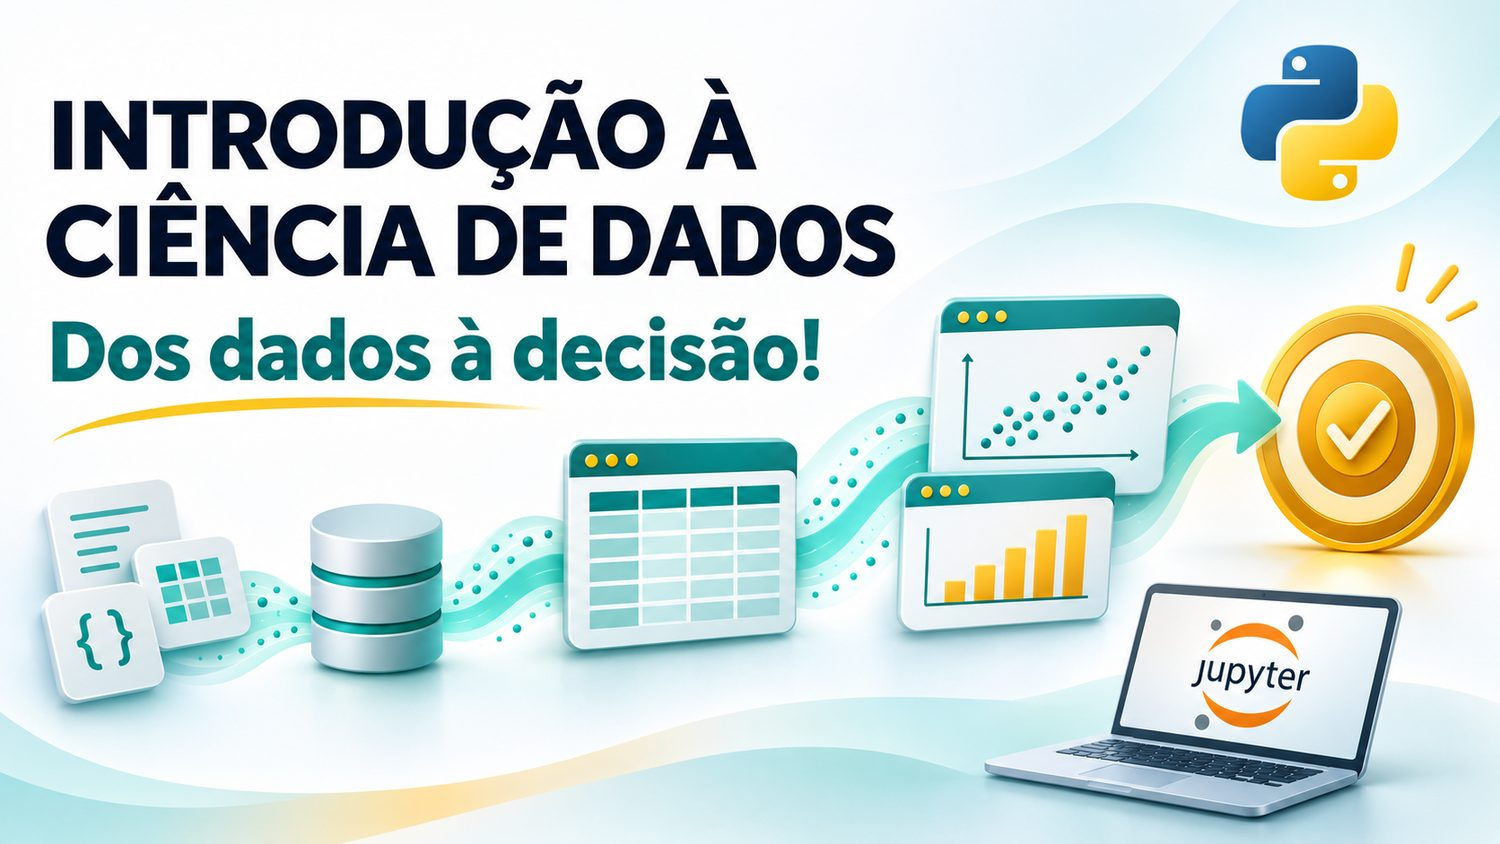

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Ci%C3%AAncia%20de%20Dados/tutorial_ciencia_dados/modulo_4_preparar_os_dados/04_Escalas.ipynb)

# Capítulo 4 – Escalas

Um carro tem 9 anos, 120 000 quilómetros e 110 cavalos. Para uma pessoa, são três medidas diferentes. Para um algoritmo que calcula distâncias, são três números, e o maior manda. Este capítulo mostra o que acontece quando os atributos têm escalas muito diferentes, as três formas habituais de as igualar e que modelos precisam disso.

> **Objetivos:** explicar porque as escalas afetam os modelos baseados em distâncias; aplicar a padronização (Z-score), a normalização Min-Max e a escala robusta; escolher entre elas conforme a presença de valores extremos; identificar os modelos que precisam de escalas iguais; aprender a escala só no treino; usar o logaritmo para variáveis muito assimétricas.

**Pré-requisitos:** capítulos 1 a 3 deste módulo, e o capítulo 3 do módulo 3 (medidas descritivas).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch, FancyBboxPatch

# Cores usadas em todo o tutorial (sempre com o mesmo significado)
AZUL, VERDE, VIOLETA, LARANJA = "#2a78d6", "#1baf7a", "#6250d6", "#eb6834"
BOM, MAU, AVISO, CINZA, TINTA = "#0ca30c", "#d03b3b", "#fab219", "#b4bdc8", "#131c26"

plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})


def tela(largura, altura, tamanho=(10, 3)):
    """Cria uma figura vazia, sem eixos, para desenhar esquemas."""
    fig, ax = plt.subplots(figsize=tamanho)
    ax.set_xlim(0, largura)
    ax.set_ylim(0, altura)
    ax.axis("off")
    return fig, ax


def caixa(ax, x, y, largura, altura, texto, cor, tamanho=10, negrito=False):
    """Desenha uma caixa arredondada com texto centrado."""
    ax.add_patch(FancyBboxPatch((x, y), largura, altura, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=cor + "30", ec=cor, lw=1.6))
    ax.text(x + largura / 2, y + altura / 2, texto, ha="center", va="center", color=TINTA,
            fontsize=tamanho, linespacing=1.45, fontweight="bold" if negrito else "normal")


def seta(ax, inicio, fim, cor="#465463", **opcoes):
    """Desenha uma seta entre dois pontos."""
    opcoes.setdefault("arrowstyle", "-|>")
    ax.add_patch(FancyArrowPatch(inicio, fim, mutation_scale=14, color=cor, lw=1.5, **opcoes))

In [2]:
def gerar_carros(n=3000, semente=17):
    """Gera anúncios de carros usados de um stand fictício (dados sintéticos; as marcas são inventadas)."""
    rng = np.random.default_rng(semente)
    segmentos = {"citadino": (11000, 75), "utilitário": (15000, 100), "familiar": (21000, 130),
                 "SUV": (27000, 150), "monovolume": (23000, 125), "desportivo": (38000, 240)}
    marcas = {"Alba": 1.00, "Boreal": 0.92, "Cimo": 1.08, "Dueto": 0.95, "Estela": 1.30, "Faro": 1.00,
              "Gávea": 0.88, "Hera": 1.45, "Ípsilon": 1.05, "Jade": 0.97, "Kappa": 1.60, "Lume": 0.90}
    frequencia = np.array([18, 16, 14, 12, 9, 9, 7, 5, 4, 3, 2, 1], dtype=float)
    segmento = rng.choice(list(segmentos), n, p=[0.24, 0.28, 0.18, 0.18, 0.08, 0.04])
    marca = rng.choice(list(marcas), n, p=frequencia / frequencia.sum())
    ano = rng.integers(2008, 2026, n)
    idade = 2026 - ano
    km = (idade * 14000 * rng.lognormal(0, 0.35, n) + rng.uniform(500, 6000, n)).round(-2)
    potencia = np.array([segmentos[s][1] for s in segmento]) * rng.normal(1, 0.12, n)
    prob_eletrico = np.clip((ano - 2016) * 0.03, 0, 0.25)
    sorteio = rng.random(n)
    combustivel = np.where(sorteio < prob_eletrico, "elétrico", np.where(sorteio < prob_eletrico + 0.15, "híbrido",
                           np.where(sorteio < prob_eletrico + 0.55, "gasóleo", "gasolina")))
    caixa_velocidades = np.where(rng.random(n) < 0.25 + 0.4 * (combustivel == "elétrico"), "automática", "manual")
    niveis = np.array(["mau", "razoável", "bom", "excelente"])
    estado = niveis[np.clip(rng.normal(2.2 - 0.06 * idade, 0.8, n).round(), 0, 3).astype(int)]
    fator_estado = pd.Series(estado).map({"mau": 0.78, "razoável": 0.92, "bom": 1.0, "excelente": 1.08}).to_numpy()
    ruido = rng.lognormal(0, 0.10, n)                      # o que o preço tem de «caro» ou de «barato» sem explicação
    preco = (np.array([segmentos[s][0] for s in segmento]) * np.array([marcas[m] for m in marca])
             * np.exp(-0.085 * idade) * np.exp(-km / 420000) * fator_estado
             * np.where(caixa_velocidades == "automática", 1.08, 1.0)
             * np.where(combustivel == "elétrico", 1.25, np.where(combustivel == "híbrido", 1.12, 1.0))
             * (potencia / np.array([segmentos[s][1] for s in segmento])) ** 0.4 * ruido)
    carros = pd.DataFrame({
        "marca": marca, "segmento": segmento, "ano": ano, "km": km, "potencia_cv": potencia.round(),
        "combustivel": combustivel, "caixa": caixa_velocidades, "estado": estado,
        "cor": rng.choice(["branco", "cinzento", "preto", "azul", "vermelho"], n), "preco": preco.round(-1)})
    nivel = pd.Series(estado).map({"mau": 0, "razoável": 1, "bom": 2, "excelente": 3}).to_numpy()
    z = (-0.2 + 0.75 * (nivel - 1.5) - 0.07 * idade + 0.7 * np.isin(segmento, ["SUV", "utilitário"])
         + 0.5 * (caixa_velocidades == "automática") - 5 * np.log(ruido))
    carros["vendido_30_dias"] = rng.random(n) < 1 / (1 + np.exp(-z))
    # Valores em falta: quem tem muitos quilómetros «esquece-se» mais vezes de os indicar
    carros.loc[rng.random(n) < 0.03 + 0.25 * (km > np.quantile(km, 0.8)), "km"] = np.nan
    carros.loc[rng.random(n) < 0.06, "potencia_cv"] = np.nan
    carros.loc[rng.random(n) < 0.05, "estado"] = np.nan
    return carros


carros = gerar_carros()
carros.head()

,marca,segmento,ano,km,potencia_cv,combustivel,caixa,estado,cor,preco,vendido_30_dias
0,Boreal,SUV,2019,127500.0,199.0,híbrido,automática,razoável,cinzento,15250.0,False
1,Gávea,citadino,2012,171200.0,67.0,gasolina,manual,bom,azul,1630.0,False
2,Gávea,familiar,2018,123900.0,116.0,gasóleo,automática,bom,preto,6670.0,True
3,Cimo,utilitário,2009,239000.0,98.0,gasolina,manual,bom,cinzento,2350.0,False
4,Boreal,citadino,2016,122600.0,51.0,gasóleo,manual,bom,branco,3080.0,False


In [3]:
from sklearn.model_selection import train_test_split

dados = carros.dropna(subset=["km", "potencia_cv"]).assign(idade=lambda t: 2026 - t["ano"]).reset_index(drop=True)
atributos = ["idade", "km", "potencia_cv"]
treino, teste = train_test_split(dados, test_size=0.25, random_state=0)
treino[atributos].describe().loc[["min", "50%", "max", "std"]].round(0)

,idade,km,potencia_cv
min,1.0,9200.0,51.0
50%,10.0,125800.0,109.0
max,18.0,806900.0,307.0
std,5.0,93625.0,40.0


A idade vai de 1 a 18; a potência, de umas dezenas a cerca de 300; os quilómetros, de menos de dez mil a mais de 800 000. Os desvios padrão diferem por um fator de quase vinte mil.

## O problema: quem tem os números maiores manda

O modelo dos vizinhos mais próximos propõe um preço a partir dos carros «mais parecidos». Parecido quer dizer **perto**, e a distância entre dois carros calcula-se com todos os atributos ao mesmo tempo.

In [4]:
a = pd.Series({"idade": 3, "km": 60000, "potencia_cv": 110})       # o carro a avaliar
b = pd.Series({"idade": 15, "km": 60500, "potencia_cv": 75})       # muito mais velho e mais fraco, com quase os mesmos km
c = pd.Series({"idade": 3, "km": 68000, "potencia_cv": 110})       # igual em tudo, com mais 8 000 km


def distancia(u, v):
    return float(np.sqrt(((u - v) ** 2).sum()))


print(pd.DataFrame({"A (a avaliar)": a, "B": b, "C": c}).T, "\n")
print(f"Distância de A a B: {distancia(a, b):>8.0f}")
print(f"Distância de A a C: {distancia(a, c):>8.0f}")

               idade     km  potencia_cv
A (a avaliar)      3  60000          110
B                 15  60500           75
C                  3  68000          110 

Distância de A a B:      501
Distância de A a C:     8000


Para o algoritmo, o carro B (doze anos mais velho e com menos 35 cavalos) é dezasseis vezes «mais parecido» com A do que o carro C, que só difere em 8 000 quilómetros. Os quilómetros contam tudo, e os outros dois atributos quase nada, apenas porque os seus números são maiores.

Em termos gerais: a distância soma os quadrados das diferenças, e uma diferença de 8 000 ao quadrado esmaga uma diferença de 12 ao quadrado.

A figura seguinte mostra os vinte vizinhos de um carro, antes e depois de pôr os atributos na mesma escala.

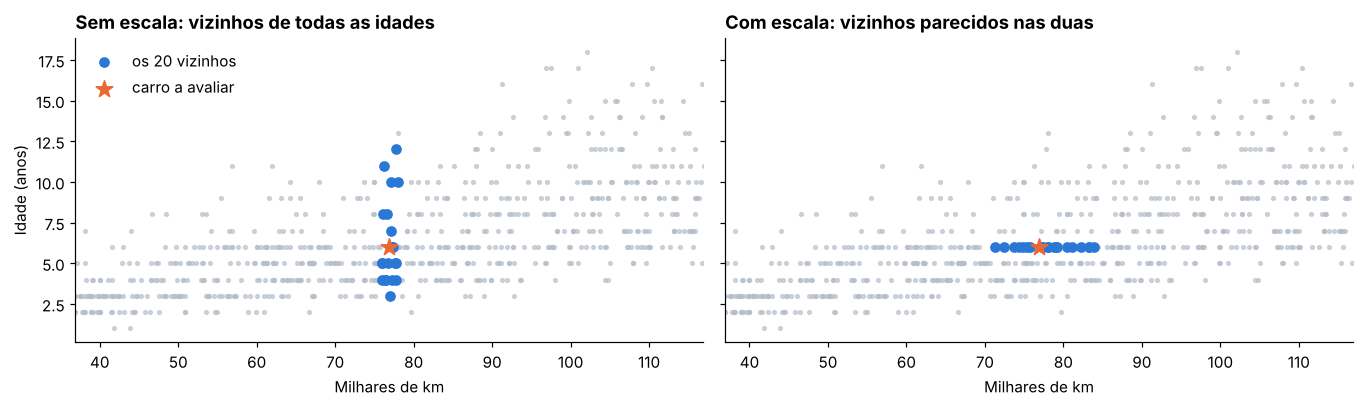

In [5]:
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler

alvo = treino[(treino["idade"] == 6) & treino["km"].between(70000, 100000)].iloc[[0]]
pares = ["idade", "km"]
vizinhos_brutos = NearestNeighbors(n_neighbors=21).fit(treino[pares]).kneighbors(alvo[pares])[1][0][1:]
escala = StandardScaler().fit(treino[pares])
vizinhos_escala = NearestNeighbors(n_neighbors=21).fit(escala.transform(treino[pares])).kneighbors(escala.transform(alvo[pares]))[1][0][1:]

fig, eixos = plt.subplots(1, 2, figsize=(12.5, 3.8), sharey=True)
for ax, indices, titulo in zip(eixos, [vizinhos_brutos, vizinhos_escala], ["Sem escala: vizinhos de todas as idades", "Com escala: vizinhos parecidos nas duas"]):
    ax.scatter(treino["km"] / 1000, treino["idade"], s=6, color=CINZA, alpha=0.6)
    ax.scatter(treino.iloc[indices]["km"] / 1000, treino.iloc[indices]["idade"], s=36, color=AZUL, zorder=3, label="os 20 vizinhos")
    ax.scatter(alvo["km"] / 1000, alvo["idade"], s=130, color=LARANJA, marker="*", zorder=4, label="carro a avaliar")
    ax.set_xlim(alvo["km"].iloc[0] / 1000 - 40, alvo["km"].iloc[0] / 1000 + 40)
    ax.set_xlabel("Milhares de km")
    ax.set_title(titulo)
eixos[0].set_ylabel("Idade (anos)")
eixos[0].legend(frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

Sem escala, os vizinhos formam uma coluna vertical: têm quase exatamente os mesmos quilómetros e idades entre os 3 e os 12 anos. Com escala, têm todos a idade do carro a avaliar e quilómetros próximos dos dele: são parecidos nas duas medidas. Só os segundos servem para propor um preço.

## Três formas de mudar a escala

| Método | Fórmula | Resultado | No scikit-learn |
| --- | --- | --- | --- |
| **Padronização** (Z-score) | (x − média) ÷ desvio padrão | Média 0, desvio padrão 1 | `StandardScaler` |
| **Normalização Min-Max** | (x − mínimo) ÷ (máximo − mínimo) | Valores entre 0 e 1 | `MinMaxScaler` |
| **Escala robusta** | (x − mediana) ÷ amplitude interquartil | Mediana 0; a metade central dos dados fica com amplitude 1 | `RobustScaler` |

As três são mudanças de unidade: deslocam e esticam o eixo, sem alterar a ordem dos valores nem a forma da distribuição. Um Z-score de 2 lê-se «dois desvios padrão acima da média», seja qual for a variável.

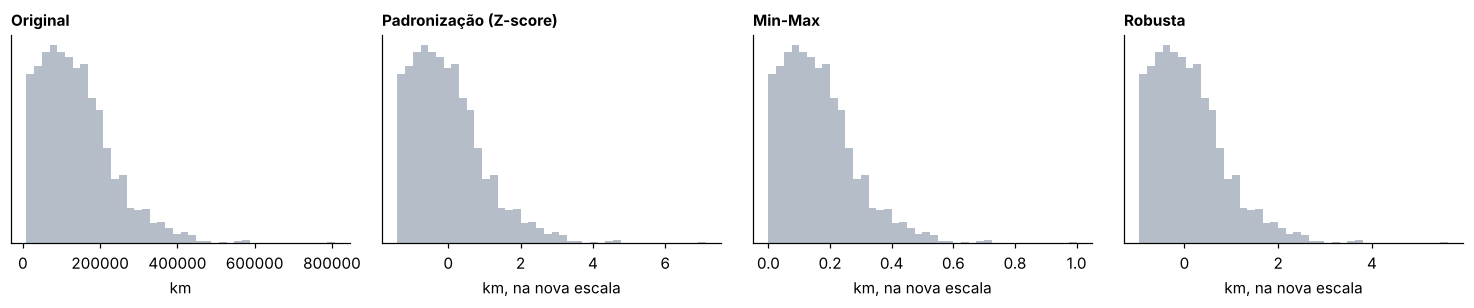

In [6]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

metodos = {"Original": None, "Padronização (Z-score)": StandardScaler(), "Min-Max": MinMaxScaler(), "Robusta": RobustScaler()}
fig, eixos = plt.subplots(1, 4, figsize=(13.5, 2.9))
for ax, (nome, metodo) in zip(eixos, metodos.items()):
    valores = treino[["km"]].to_numpy() if metodo is None else metodo.fit_transform(treino[["km"]])
    ax.hist(valores.ravel(), bins=40, color=CINZA)
    ax.set_title(nome, fontsize=10)
    ax.set_yticks([])
    ax.set_xlabel("km" if metodo is None else "km, na nova escala")
plt.tight_layout()
plt.show()

Os quatro histogramas têm exatamente a mesma forma. Só mudam os números do eixo.

### O efeito de um valor extremo

As três diferem na forma como reagem a valores extremos. Vamos acrescentar aos dados um carro com um erro de registo: 4 000 000 de quilómetros, um zero a mais.

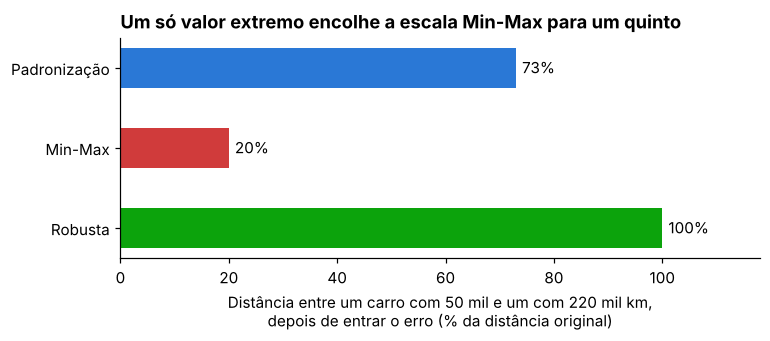

,amplitude sem o erro,amplitude com o erro,fica com (%)
Padronização,1.816,1.330,73.0
Min-Max,0.213,0.043,20.0
Robusta,1.401,1.400,100.0


In [7]:
com_erro = np.append(treino["km"].to_numpy(), 4_000_000).reshape(-1, 1)
tipico = np.array([[50_000], [125_000], [220_000]])          # três carros normais: poucos, médios e muitos km

linhas = {}
for nome, metodo in [("Padronização", StandardScaler()), ("Min-Max", MinMaxScaler()), ("Robusta", RobustScaler())]:
    sem = metodo.fit(treino[["km"]].to_numpy()).transform(tipico).ravel()
    com = metodo.fit(com_erro).transform(tipico).ravel()
    linhas[nome] = {"amplitude sem o erro": sem[2] - sem[0], "amplitude com o erro": com[2] - com[0]}
tabela = pd.DataFrame(linhas).T
tabela["fica com (%)"] = (tabela["amplitude com o erro"] / tabela["amplitude sem o erro"] * 100).round(0)

fig, ax = plt.subplots(figsize=(7.5, 2.6))
barras = ax.barh(tabela.index, tabela["fica com (%)"], color=[AZUL, MAU, BOM], height=0.5)
ax.bar_label(barras, fmt="%.0f%%", padding=4)
ax.invert_yaxis()
ax.set_xlim(0, 118)
ax.set_xlabel("Distância entre um carro com 50 mil e um com 220 mil km,\ndepois de entrar o erro (% da distância original)")
ax.set_title("Um só valor extremo encolhe a escala Min-Max para um quinto")
plt.show()

tabela.round(3)

A escala Min-Max usa o mínimo e o máximo. Um único valor absurdo passa a ser o novo máximo, e todos os carros normais ficam espremidos num canto do intervalo: a variável quase deixa de distinguir um carro com poucos quilómetros de um com muitos. A padronização também sofre, porque o valor extremo aumenta o desvio padrão. A escala robusta, que usa a mediana e os quartis, não se altera.

| Situação | Escolha habitual |
| --- | --- |
| Sem valores extremos importantes | Padronização |
| É preciso um intervalo fixo (por exemplo, entre 0 e 1) e não há valores extremos | Min-Max |
| Há valores extremos que não se podem corrigir | Robusta |
| Não se sabe | Padronização, depois de olhar para os histogramas |

## O efeito no modelo

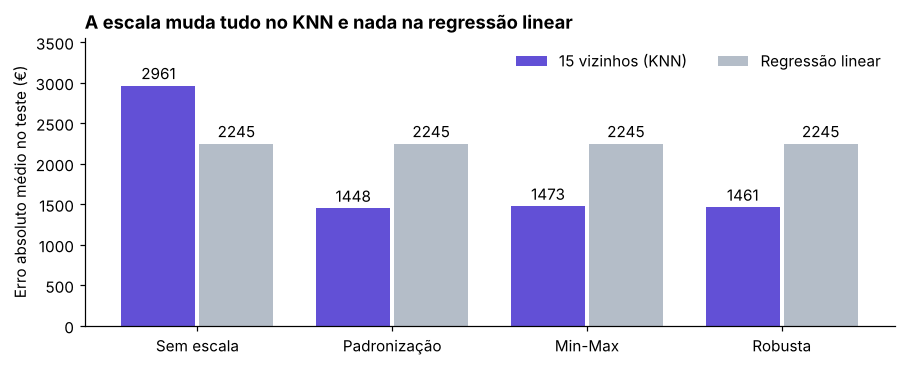

In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.neighbors import KNeighborsRegressor

X_treino, X_teste = treino[atributos], teste[atributos]
y_treino, y_teste = treino["preco"], teste["preco"]


def erro(modelo, escala=None):
    A, B = (X_treino, X_teste) if escala is None else (escala.fit_transform(X_treino), escala.transform(X_teste))
    return mean_absolute_error(y_teste, modelo.fit(A, y_treino).predict(B))


resultados = pd.DataFrame({
    "Sem escala": [erro(KNeighborsRegressor(15)), erro(LinearRegression())],
    "Padronização": [erro(KNeighborsRegressor(15), StandardScaler()), erro(LinearRegression(), StandardScaler())],
    "Min-Max": [erro(KNeighborsRegressor(15), MinMaxScaler()), erro(LinearRegression(), MinMaxScaler())],
    "Robusta": [erro(KNeighborsRegressor(15), RobustScaler()), erro(LinearRegression(), RobustScaler())]},
    index=["15 vizinhos (KNN)", "Regressão linear"])

x = np.arange(4)
fig, ax = plt.subplots(figsize=(9.5, 3.4))
b1 = ax.bar(x - 0.2, resultados.loc["15 vizinhos (KNN)"], 0.38, color=VIOLETA, label="15 vizinhos (KNN)")
b2 = ax.bar(x + 0.2, resultados.loc["Regressão linear"], 0.38, color=CINZA, label="Regressão linear")
ax.bar_label(b1, fmt="%.0f", padding=2)
ax.bar_label(b2, fmt="%.0f", padding=2)
ax.set_xticks(x, resultados.columns)
ax.set_ylabel("Erro absoluto médio no teste (€)")
ax.set_ylim(0, resultados.max().max() * 1.2)
ax.set_title("A escala muda tudo no KNN e nada na regressão linear")
ax.legend(frameon=False, ncol=2, loc="upper right")
plt.show()

Com qualquer das três escalas, o erro do KNN cai para cerca de metade, e passa a bater a regressão linear por larga margem, em vez de perder para ela. No capítulo 2 tínhamos concluído que o KNN era o pior dos dois: estava só mal preparado.

A regressão linear dá exatamente o mesmo erro com e sem escala. Não mede distâncias: multiplica cada atributo por um coeficiente, e quando o atributo muda de unidade o coeficiente compensa.

### Que modelos precisam de escala

| Precisam | Porquê |
| --- | --- |
| KNN | Baseia-se em distâncias |
| K-Means e agrupamento hierárquico (módulo 7) | Baseiam-se em distâncias |
| Análise de componentes principais, PCA (módulo 7) | Procura as direções de maior variância, que dependem da unidade |
| Modelos lineares com regularização; redes neuronais | A penalização e a otimização tratam os coeficientes por igual |

| Não precisam | Porquê |
| --- | --- |
| Árvores de decisão e os seus conjuntos (módulo 6) | Só perguntam «é maior do que…?»; a ordem não muda com a escala |
| Regressão linear simples | Os coeficientes absorvem a unidade |

Na dúvida, mudar a escala raramente prejudica. Não a mudar, quando era precisa, estraga o modelo sem dar erro.

## Aprender a escala no treino

A média e o desvio padrão usados na padronização são **aprendidos com os dados**, como a mediana da imputação (capítulo 3). A regra é a mesma.

In [9]:
escala = StandardScaler()
escala.fit(X_treino)                                   # aprende a média e o desvio padrão no treino
treino_na_escala = escala.transform(X_treino)
teste_na_escala = escala.transform(X_teste)            # aplica AS MESMAS média e desvio ao teste

print("Médias aprendidas:  ", dict(zip(atributos, escala.mean_.round(1).tolist())))
print("Desvios aprendidos: ", dict(zip(atributos, escala.scale_.round(1).tolist())))
print("\nMédias do treino na nova escala:", treino_na_escala.mean(axis=0).round(3))
print("Médias do teste na nova escala: ", teste_na_escala.mean(axis=0).round(3))

Médias aprendidas:   {'idade': 9.5, 'km': 140836.3, 'potencia_cv': 115.4}
Desvios aprendidos:  {'idade': 5.2, 'km': 93601.6, 'potencia_cv': 40.4}

Médias do treino na nova escala: [ 0.  0. -0.]
Médias do teste na nova escala:  [ 0.017  0.002 -0.03 ]


As médias do treino ficam exatamente em zero. As do teste ficam **perto** de zero, e é assim que deve ser: o teste foi transformado com os números do treino, como acontecerá com cada carro novo que chegar ao stand. Um carro novo chega sozinho; não tem média nem desvio padrão próprios.

`fit_transform` faz as duas operações de seguida e só se usa no treino. No teste usa-se sempre `transform`.

## Quando o problema é a forma: o logaritmo

Mudar a escala não altera a forma da distribuição. Os preços têm uma cauda comprida à direita, e continuam a tê-la depois de padronizados.

Para variáveis sempre positivas e muito assimétricas (preços, rendimentos, populações), usa-se o **logaritmo**, que comprime os valores grandes e estica os pequenos.

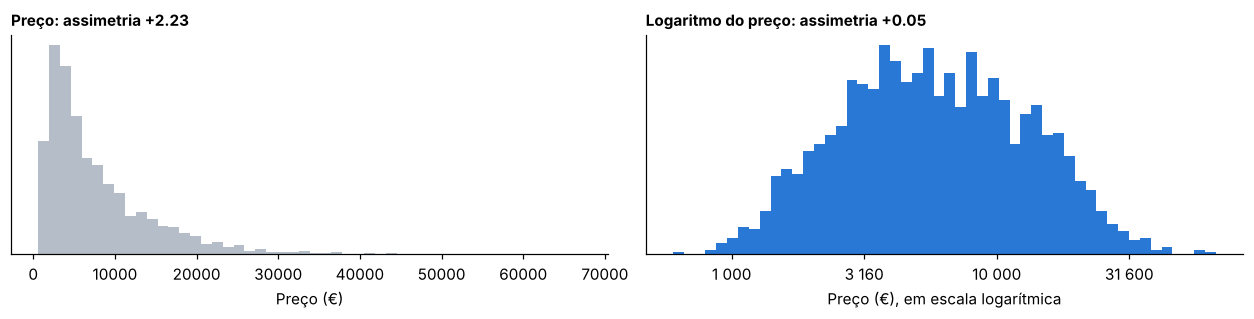

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 3))
ax1.hist(treino["preco"], bins=50, color=CINZA)
ax1.set_title(f"Preço: assimetria {treino['preco'].skew():+.2f}", fontsize=10)
ax1.set_xlabel("Preço (€)")
ax2.hist(np.log10(treino["preco"]), bins=50, color=AZUL)
ax2.set_xticks([3, 3.5, 4, 4.5], ["1 000", "3 160", "10 000", "31 600"])
ax2.set_title(f"Logaritmo do preço: assimetria {np.log10(treino['preco']).skew():+.2f}", fontsize=10)
ax2.set_xlabel("Preço (€), em escala logarítmica")
for ax in (ax1, ax2):
    ax.set_yticks([])
plt.tight_layout()
plt.show()

Na escala logarítmica, distâncias iguais correspondem a **razões** iguais: de 1 000 € para 2 000 € vai o mesmo que de 10 000 € para 20 000 €. Para preços, é a forma natural de pensar: um erro de 500 € é grave num carro de 2 000 € e irrelevante num de 40 000 €.

O logaritmo também se pode aplicar ao **alvo**. Um modelo treinado para prever o logaritmo do preço erra em percentagem, e não em euros.

In [11]:
def erro_percentual(y_real, y_previsto):
    return float(np.mean(np.abs(y_previsto - y_real) / y_real) * 100)


direto = LinearRegression().fit(X_treino, y_treino).predict(X_teste)
com_log = 10 ** LinearRegression().fit(X_treino, np.log10(y_treino)).predict(X_teste)

comparacao = pd.DataFrame({"Erro absoluto médio (€)": [mean_absolute_error(y_teste, direto), mean_absolute_error(y_teste, com_log)],
                           "Erro percentual médio (%)": [erro_percentual(y_teste, direto), erro_percentual(y_teste, com_log)],
                           "Preços negativos previstos": [int((direto < 0).sum()), int((com_log < 0).sum())]},
                          index=["Prever o preço", "Prever o logaritmo do preço"])
comparacao.round(1)

,Erro absoluto médio (€),Erro percentual médio (%),Preços negativos previstos
Prever o preço,2245.1,44.4,48
Prever o logaritmo do preço,1544.6,19.3,0


O modelo que prevê o logaritmo tem menos de metade do erro percentual e nunca propõe preços negativos, o que a regressão linear direta faz para dezenas de carros velhos. Aqui ganha também em euros, porque um carro perde valor mais como uma percentagem por ano do que como um valor fixo por ano: a reta ajusta-se melhor ao logaritmo do preço do que ao preço.

Não é sempre assim. Um modelo treinado no logaritmo dá o mesmo peso a um erro de 10% num carro de 2 000 € e num de 40 000 €. Qual dos dois é melhor depende da medida de desempenho, o **P** do capítulo 1: se ao stand custam sobretudo os euros de erro nos carros caros, convém comparar as duas versões nessa medida.

## Exercícios

### `Exercício 1` – À mão

Três carros têm 40, 100 e 160 mil quilómetros. Calcula, sem bibliotecas, os valores depois da padronização e depois da escala Min-Max. Depois confirma com o scikit-learn.

In [12]:
# Escreve aqui o código do exercício 1

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
v = np.array([40.0, 100.0, 160.0])
print("Z-score:", (v - v.mean()) / v.std())          # o StandardScaler divide por n, como o NumPy
print("Min-Max:", (v - v.min()) / (v.max() - v.min()))
print(StandardScaler().fit_transform(v.reshape(-1, 1)).ravel(), MinMaxScaler().fit_transform(v.reshape(-1, 1)).ravel())
```

Z-score: −1,22; 0; +1,22. Min-Max: 0; 0,5; 1. Repara que o `StandardScaler` usa o desvio padrão que divide por n. Com poucos valores, a diferença para o do pandas (que divide por n − 1) nota-se; com milhares, não.

</details>

### `Exercício 2` – Que escala?

Indica a escala que escolherias, ou se não é precisa:

1. Um KNN com a idade e o rendimento de clientes, em que alguns rendimentos são dezenas de vezes superiores à mediana.
2. Uma árvore de decisão com as mesmas variáveis.
3. Um K-Means com temperatura (°C), humidade (%) e pressão (hPa), todas sem valores extremos.
4. Uma rede neuronal que recebe imagens com pixéis de 0 a 255.

<details>
<summary><b>Ver uma solução possível</b></summary>

1. Robusta, ou o logaritmo do rendimento seguido de padronização.
2. Não é precisa.
3. Padronização.
4. Min-Max: dividir por 255 põe os valores entre 0 e 1, e não há valores extremos possíveis.

</details>

### `Exercício 3` – O efeito do número de vizinhos, com escala

No capítulo 2, o melhor número de vizinhos sem escala era muito alto. Repete a procura com os atributos padronizados (usa uma parte do treino como validação). O melhor valor mudou? Porquê?

In [13]:
# Escreve aqui o código do exercício 3

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
ajuste, validacao = train_test_split(treino, test_size=0.25, random_state=0)
e = StandardScaler().fit(ajuste[atributos])
for k in [1, 3, 5, 8, 12, 18, 25, 40, 60, 100]:
    m = KNeighborsRegressor(k).fit(e.transform(ajuste[atributos]), ajuste["preco"])
    print(k, round(mean_absolute_error(validacao["preco"], m.predict(e.transform(validacao[atributos])))))
```

Com escala, o melhor número de vizinhos é muito mais baixo. Sem escala, os «vizinhos» eram carros com os mesmos quilómetros e idades quaisquer, e só a média de muitos dava alguma coisa útil. Com vizinhos realmente parecidos, bastam poucos.

</details>

### `Exercício 4` – Fuga ou não?

Um colega escreve `X = StandardScaler().fit_transform(X)` e só depois chama `train_test_split`. Mede a diferença no erro do KNN em relação à forma correta. A diferença é grande? Então porque é que a regra existe?

In [14]:
# Escreve aqui o código do exercício 4

<details>
<summary><b>Ver uma solução possível</b></summary>

```python
tudo = StandardScaler().fit_transform(dados[atributos])
A, B, ya, yb = train_test_split(tudo, dados["preco"], test_size=0.25, random_state=0)
errado = mean_absolute_error(yb, KNeighborsRegressor(15).fit(A, ya).predict(B))
print(f"Escala antes da divisão: {errado:.0f} € | forma correta: {erro(KNeighborsRegressor(15), StandardScaler()):.0f} €")
```

A diferença é de poucos euros: com milhares de carros, a média e o desvio padrão quase não mudam por incluírem o teste. A regra existe por três razões: a diferença deixa de ser pequena com poucos dados ou com valores extremos no teste; outras operações feitas antes da divisão (escolher atributos, por exemplo) causam fugas enormes (capítulo 6); e um hábito que está sempre certo é mais seguro do que avaliar caso a caso.

</details>

## Verifica o que aprendeste

- [ ] Sei explicar porque as escalas afetam as distâncias.
- [ ] Sei aplicar a padronização, a escala Min-Max e a escala robusta, e interpretar um Z-score.
- [ ] Sei qual das três resiste a valores extremos, e porquê.
- [ ] Sei que modelos precisam de escalas iguais e quais não precisam.
- [ ] Sei a diferença entre `fit`, `transform` e `fit_transform`, e onde se usa cada um.
- [ ] Sei quando usar o logaritmo, e o que muda ao aplicá-lo ao alvo.

## Leitura recomendada

- https://scikit-learn.org/stable/modules/preprocessing.html
- https://scikit-learn.org/stable/auto_examples/preprocessing/plot_all_scaling.html
- https://en.wikipedia.org/wiki/Feature_scaling
- https://en.wikipedia.org/wiki/Standard_score